# Mô hình LightGBM (LightGBM Regression) Dự Báo Giá Cổ Phiếu Apple (AAPL)

- **Mục tiêu:** Dự báo biến động giá ngày kế tiếp (`Delta = NextPrice - Price`), sau đó khôi phục lại giá dự báo $\text{NextPrice} = \text{Price} + \text{Delta}$.
- **Dữ liệu:** Giá cổ phiếu Apple (`Apple_Stock_ready.csv`) gồm 8 đặc trưng cơ sở: `Price`, `Open`, `High`, `Low`, `Volume`, `Return_1`, `High_Low_Range`, `Open_Close_Change`.
- **Phương pháp:** Mô hình cây quyết định Gradient Boosting (LightGBM Regressor), tối ưu hóa siêu tham số bằng `TimeSeriesSplit(n_splits=5)` và `GridSearchCV`.

## 1. Khai báo các thư viện cần thiết

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import lightgbm as lgb

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

## 2. Đọc dữ liệu từ GitHub
Tải tập dữ liệu đã qua tiền xử lý `Apple_Stock_ready.csv` từ GitHub repository của nhóm và sắp xếp theo thứ tự thời gian tăng dần.

In [2]:
# ============================================================
# 1. ĐỌC DỮ LIỆU TỪ GITHUB
# ============================================================

url = "https://raw.githubusercontent.com/nguyenkhachuy2006-eng/is403/main/Cleaned%20data/Apple_Stock_ready.csv"

try:
    df = pd.read_csv(url, parse_dates=["Date"])
except Exception:
    df = pd.read_csv("../Cleaned data/Apple_Stock_ready.csv", parse_dates=["Date"])

df = df.sort_values("Date").reset_index(drop=True)

## 3. Chọn đúng 8 feature cơ sở và tạo biến mục tiêu (Delta)
- 8 đặc trưng: `Price`, `Open`, `High`, `Low`, `Volume`, `Return_1`, `High_Low_Range`, `Open_Close_Change`.
- Biến mục tiêu: $\text{Delta} = \text{NextPrice} - \text{Price}$.

In [3]:
# ============================================================
# 2. CHỌN ĐÚNG 8 FEATURE CƠ SỞ
# ============================================================

feature_cols = [
    "Price",
    "Open",
    "High",
    "Low",
    "Volume",
    "Return_1",
    "High_Low_Range",
    "Open_Close_Change"
]

# Loại bỏ các dòng thiếu dữ liệu
df = df.dropna(
    subset=feature_cols + ["NextPrice"]
).reset_index(drop=True)

# Target: Biến động giá ngày tiếp theo
df["Delta"] = df["NextPrice"] - df["Price"]

print("=== THÔNG TIN DỮ LIỆU ===")
print("Số lượng feature:", len(feature_cols))
print("Feature sử dụng:", feature_cols)
print("Tổng số dòng:", len(df))

=== THÔNG TIN DỮ LIỆU ===
Số lượng feature: 8
Feature sử dụng: ['Price', 'Open', 'High', 'Low', 'Volume', 'Return_1', 'High_Low_Range', 'Open_Close_Change']
Tổng số dòng: 4020


## 4. Chia tập dữ liệu Train / Validation / Test theo thời gian
- Tỷ lệ: 80% cho tập Train toàn bộ (Full Train), 20% cho tập Test.
- Trong tập Full Train, tách tiếp 90% cho `train_fit` và 10% cho `train_val` để kiểm định mô hình trước khi đánh giá trên Test.

In [4]:
# ============================================================
# 3. CHIA TRAIN / VALIDATION / TEST THEO THỜI GIAN
# ============================================================

n = len(df)
i_train = int(n * 0.80)

train = df.iloc[:i_train].copy()
test = df.iloc[i_train:].copy()

i_val = int(len(train) * 0.90)

train_fit = train.iloc[:i_val].copy()
train_val = train.iloc[i_val:].copy()

print("\n=== CHIA DỮ LIỆU ===")
print(f"Train_fit: {len(train_fit)}")
print(f"Train_val: {len(train_val)}")
print(f"Test: {len(test)}")

# Feature và Target (Delta)
X_fit = train_fit[feature_cols]
y_fit = train_fit["Delta"]

X_val = train_val[feature_cols]
y_val = train_val["Delta"]

X_full_train = train[feature_cols]
y_full_train = train["Delta"]

X_test = test[feature_cols]
y_test = test["Delta"]


=== CHIA DỮ LIỆU ===
Train_fit: 2894
Train_val: 322
Test: 804


## 5. Xây dựng mô hình LightGBM với TimeSeriesSplit & GridSearchCV
Sử dụng `TimeSeriesSplit(n_splits=5)` và `GridSearchCV` để tối ưu hóa siêu tham số của mô hình `LGBMRegressor` trên dữ liệu chuỗi thời gian, loại bỏ hoàn toàn rủi ro rò rỉ dữ liệu (data leakage).

### Cơ sở Toán học: Mô hình cộng & Công thức cập nhật của LightGBM

#### 1. Mô hình cộng (Additive Model) & Công thức Tổng quát
$$\hat{y}_i = F_M(x_i) = F_0 + \eta \sum_{m=1}^M f_m(x_i), \quad f_m(x) = w_{q(x)}$$

* **Giải thích các ký hiệu:**
  - $\hat{y}_i$: Giá trị dự đoán cuối cùng cho mẫu $x_i$ sau $M$ cây (trong đề tài là biến động giá dự báo $\widehat{\Delta}_i = \widehat{P}_{i+1} - P_i$).
  - $F_M(x_i)$: Hàm dự báo tổng hợp sau $M$ vòng lặp boosting.
  - $F_0$: Giá trị khởi tạo ban đầu (ví dụ: trung bình của $y$ trên tập train với hàm mất mát MSE, $F_0 = \bar{y} = \overline{\Delta}_{\text{train}}$).
  - $M$: Tổng số cây quyết định được xây dựng ($M \le 500$, dừng sớm qua Early Stopping).
  - $f_m$: Cây thứ $m$ ($m = 1, 2, \dots, M$).
  - $q(x)$: Cấu trúc cây, cho biết mẫu $x$ rơi vào lá nào ($q: \mathbb{R}^p \to \{1, 2, \dots, T\}$).
  - $w_j$: Giá trị (trọng số) của lá $j$ ($j = 1, \dots, T$).
  - $\eta$: Tốc độ học (learning rate / shrinkage), giúp co hẹp đóng góp của từng cây để chống quá khớp ($\eta = 0.03$).

#### 2. Công thức Cập nhật (Additive Update Formula)
Dự đoán được cập nhật tuần tự qua từng vòng lặp:
$$\hat{y}_i^{(m)} = F_m(x_i) = F_{m-1}(x_i) + \eta f_m(x_i) = \hat{y}_i^{(m-1)} + \eta w_{q(x_i)}$$

Áp dụng trực tiếp vào bài toán dự báo biến động giá cổ phiếu Apple ($y = \Delta = P_{t+1} - P_t$):
$$\widehat{\Delta}_t^{(m)} = \widehat{\Delta}_t^{(m-1)} + \eta f_m(\mathbf{x}_t)$$
Sau $M$ vòng lặp, khôi phục giá đóng cửa ngày kế tiếp trên thang đo USD:
$$\widehat{P}_{t+1} = P_t + \widehat{\Delta}_t = P_t + \left( F_0 + \eta \sum_{m=1}^M f_m(\mathbf{x}_t) \right)$$

In [5]:
# ============================================================
# 4. XÂY DỰNG MÔ HÌNH LIGHTGBM
# ============================================================

tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    "num_leaves": [15, 31],
    "learning_rate": [0.03, 0.05],
    "n_estimators": [50, 100],
    "min_child_samples": [20, 50]
}

# GridSearchCV giúp tránh leakage trong CV
lgb_model = GridSearchCV(
    estimator=lgb.LGBMRegressor(random_state=42, verbose=-1, n_jobs=1),
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_squared_error",
    n_jobs=1,
    refit=True
)

## 6. Huấn luyện và dự báo trên tập Validation
Huấn luyện trên `X_fit`, dự báo biến động `Delta` trên `X_val` và cộng lại giá ngày hiện tại để thu được giá dự báo:
$$\text{Pred\_Val} = \text{Price}_t + \Delta_{\text{pred}}$$

In [6]:
# ============================================================
# 5. HUẤN LUYỆN VÀ DỰ BÁO VALIDATION
# ============================================================

lgb_model.fit(X_fit, y_fit)

# Dự báo Delta
delta_pred_val = lgb_model.predict(X_val)

# Khôi phục giá dự báo
pred_val = train_val["Price"].values + delta_pred_val

best_params_val = lgb_model.best_params_

## 7. Huấn luyện lại trên toàn bộ tập Train và dự báo trên tập Test
Tận dụng toàn bộ 80% dữ liệu huấn luyện (`X_full_train`) để tối ưu hóa siêu tham số và dự báo cho tập Test:
$$\text{Pred\_Test} = \text{Price}_t + \Delta_{\text{pred}}$$

In [7]:
# ============================================================
# 6. HUẤN LUYỆN LẠI TRÊN TOÀN BỘ TRAIN
# ============================================================

lgb_model.fit(X_full_train, y_full_train)

# Dự báo Delta trên Test
delta_pred_test = lgb_model.predict(X_test)

# Khôi phục giá dự báo
pred_test = test["Price"].values + delta_pred_test

best_params_test = lgb_model.best_params_

## 8. Đánh giá mô hình (MAE, RMSE, R², Directional Accuracy)
Định nghĩa hàm đánh giá các chỉ số sai số giá tuyệt đối (MAE, RMSE, R²) và độ chính xác dự báo hướng tăng/giảm (Directional Accuracy - DirAcc).

In [8]:
# ============================================================
# 7. ĐÁNH GIÁ MÔ HÌNH
# ============================================================

def metrics(y_true, y_pred, price_t):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    # Đánh giá hướng biến động
    dir_true = np.sign(y_true - price_t)
    dir_pred = np.sign(y_pred - price_t)

    diracc = np.mean(dir_true == dir_pred) * 100

    return mae, rmse, r2, diracc


# Validation
val_metrics = metrics(
    train_val["NextPrice"].values,
    pred_val,
    train_val["Price"].values
)

# Test
test_metrics = metrics(
    test["NextPrice"].values,
    pred_test,
    test["Price"].values
)

print("\n=== LIGHTGBM VALIDATION METRICS ===")
print(f"Tham số tối ưu: {best_params_val}")
print(f"MAE: {val_metrics[0]:.4f}")
print(f"RMSE: {val_metrics[1]:.4f}")
print(f"R²: {val_metrics[2]:.4f}")
print(f"DirAcc: {val_metrics[3]:.2f}%")

print("\n=== LIGHTGBM TEST METRICS ===")
print(f"Tham số tối ưu: {best_params_test}")
print(f"MAE: {test_metrics[0]:.4f}")
print(f"RMSE: {test_metrics[1]:.4f}")
print(f"R²: {test_metrics[2]:.4f}")
print(f"DirAcc: {test_metrics[3]:.2f}%")


=== LIGHTGBM VALIDATION METRICS ===
Tham số tối ưu: {'learning_rate': 0.03, 'min_child_samples': 50, 'n_estimators': 50, 'num_leaves': 15}
MAE: 2.2819
RMSE: 3.0310
R²: 0.9620
DirAcc: 48.76%

=== LIGHTGBM TEST METRICS ===
Tham số tối ưu: {'learning_rate': 0.03, 'min_child_samples': 50, 'n_estimators': 50, 'num_leaves': 31}
MAE: 2.6659
RMSE: 3.8907
R²: 0.9921
DirAcc: 51.24%


## 9. Xuất kết quả dự báo trên toàn bộ dataset vào thư mục `model_predict`
- Dự báo biến động giá trên toàn bộ tập dữ liệu (4,020 dòng) bằng mô hình LightGBM đã huấn luyện.
- Khôi phục giá dự báo `price_pred` = $\text{Price}_t + \Delta_{\text{pred}}$.
- Lưu **duy nhất 1 file CSV** vào thư mục `model_predict`:
  - `model_predict/pred_LightGBM.csv` (gồm 2 cột `Date` và `price_pred`, độ dài bằng toàn bộ dataset).

In [9]:
# ============================================================
# 8. XUẤT KẾT QUẢ DỰ BÁO TOÀN BỘ DATASET VÀO model_predict
# ============================================================

# Xác định đường dẫn thư mục model_predict
predict_dir = os.path.join("..", "model_predict") if os.path.exists("..") and os.path.basename(os.getcwd()) == "model" else "model_predict"
os.makedirs(predict_dir, exist_ok=True)

# Dự báo Delta trên toàn bộ dataset
X_all = df[feature_cols]
delta_pred_all = lgb_model.predict(X_all)

# Khôi phục giá dự báo trên toàn bộ dataset
pred_all = df["Price"].values + delta_pred_all

# Tạo DataFrame kết quả dự báo trên toàn bộ dataset
pred_full_df = pd.DataFrame({
    "Date": df["Date"].values,
    "price_pred": pred_all
})

# Xuất duy nhất 1 file CSV vào thư mục model_predict
output_csv_path = os.path.join(predict_dir, "pred_LightGBM.csv")
pred_full_df.to_csv(output_csv_path, index=False)

print(f"✓ Đã lưu thành công 1 file duy nhất vào: {output_csv_path}")
print(f"  - Số dòng: {len(pred_full_df)} (khớp toàn bộ dataset {len(df)} dòng)")
print(f"  - Các cột: {list(pred_full_df.columns)}")

# Bảng kết quả đánh giá (chỉ hiển thị, không lưu thêm file CSV riêng)
metrics_df = pd.DataFrame({
    "Dataset": ["Validation", "Test"],
    "MAE": [val_metrics[0], test_metrics[0]],
    "RMSE": [val_metrics[1], test_metrics[1]],
    "R2": [val_metrics[2], test_metrics[2]],
    "DirAcc": [val_metrics[3], test_metrics[3]],
    "Best_Params": [str(best_params_val), str(best_params_test)]
})
metrics_df

✓ Đã lưu thành công 1 file duy nhất vào: ..\model_predict\pred_LightGBM.csv
  - Số dòng: 4020 (khớp toàn bộ dataset 4020 dòng)
  - Các cột: ['Date', 'price_pred']


,Dataset,MAE,RMSE,R2,DirAcc,Best_Params
0,Validation,2.281912,3.031031,0.962016,48.757764,"{'learning_rate': 0.03, 'min_child_samples': 5..."
1,Test,2.665907,3.890705,0.992073,51.243781,"{'learning_rate': 0.03, 'min_child_samples': 5..."


## 10. Trực quan hóa kết quả (5 Biểu đồ phục vụ báo cáo)
Khởi tạo các biến cần thiết và trực quan hóa kết quả dự báo của mô hình.

In [10]:
# ============================================================
# 9. VẼ 5 BIỂU ĐỒ PHỤC VỤ BÁO CÁO
# ============================================================

actual_test = test["NextPrice"].values
dates_test = test["Date"].values

residuals = actual_test - pred_test

### Biểu đồ 1: So sánh Giá thực tế và Giá dự báo trên toàn bộ tập Test

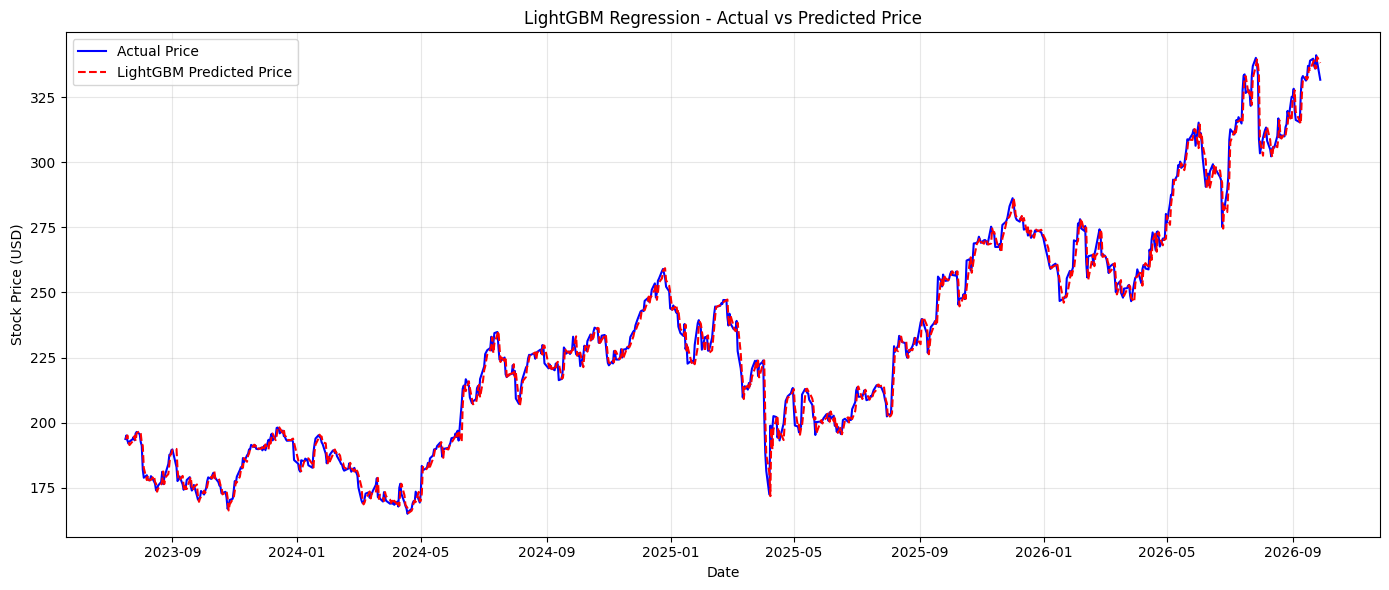

In [11]:
# ------------------------------------------------------------
# BIỂU ĐỒ 1: GIÁ THỰC TẾ VÀ GIÁ DỰ BÁO TRÊN TEST
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    dates_test, actual_test,
    label="Actual Price",
    color="blue",
    linewidth=1.5
)

plt.plot(
    dates_test, pred_test,
    label="LightGBM Predicted Price",
    color="red",
    linestyle="--",
    linewidth=1.5
)

plt.title("LightGBM Regression - Actual vs Predicted Price")
plt.xlabel("Date")
plt.ylabel("Stock Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Biểu đồ 2: So sánh chi tiết trong 100 phiên giao dịch cuối cùng của tập Test

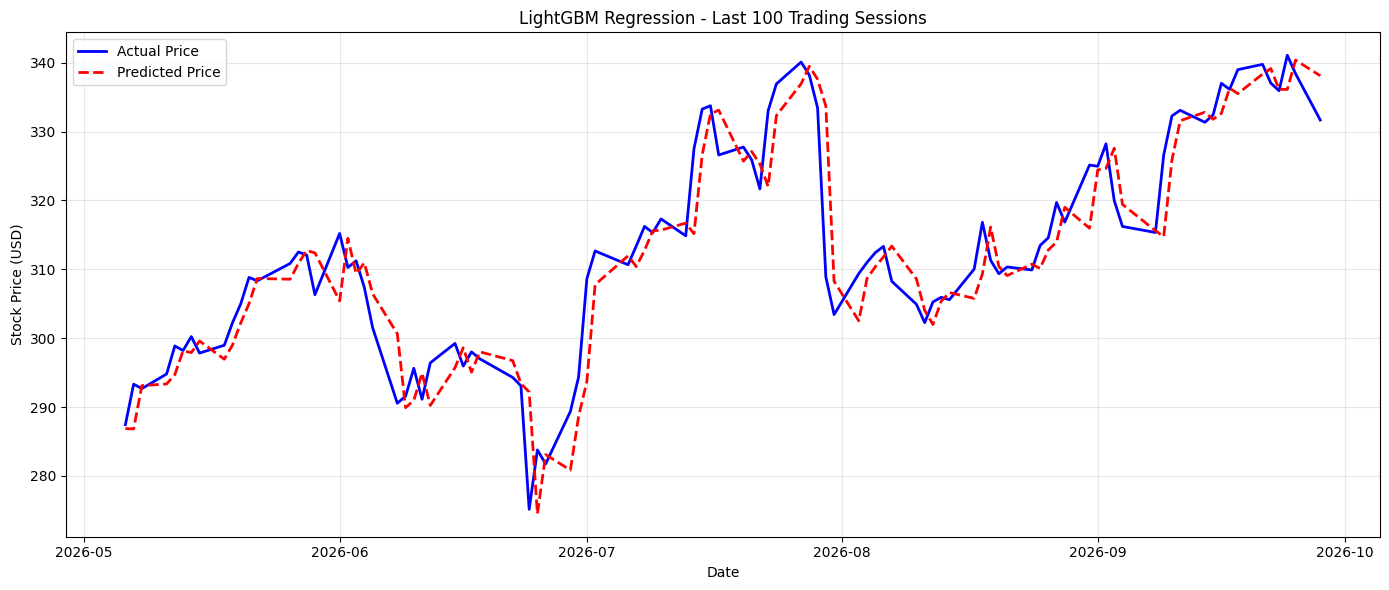

In [12]:
# ------------------------------------------------------------
# BIỂU ĐỒ 2: SO SÁNH 100 PHIÊN CUỐI CỦA TEST
# ------------------------------------------------------------

last_n = min(100, len(test))

plt.figure(figsize=(14, 6))

plt.plot(
    dates_test[-last_n:],
    actual_test[-last_n:],
    label="Actual Price",
    color="blue",
    linewidth=2
)

plt.plot(
    dates_test[-last_n:],
    pred_test[-last_n:],
    label="Predicted Price",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("LightGBM Regression - Last 100 Trading Sessions")
plt.xlabel("Date")
plt.ylabel("Stock Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Biểu đồ 3: Scatter Plot - Tương quan giữa Giá thực tế và Giá dự báo

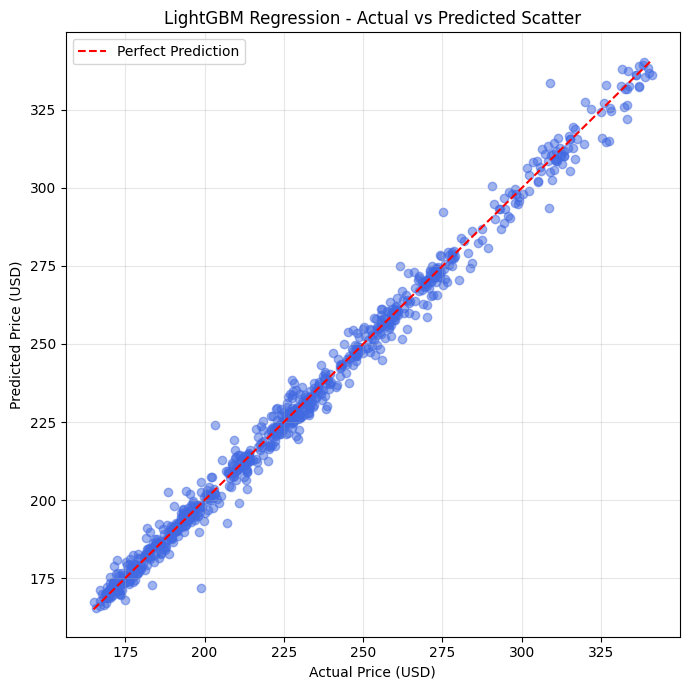

In [13]:
# ------------------------------------------------------------
# BIỂU ĐỒ 3: SCATTER ACTUAL VS PREDICTED
# ------------------------------------------------------------

plt.figure(figsize=(7, 7))

plt.scatter(
    actual_test,
    pred_test,
    alpha=0.5,
    color="royalblue"
)

min_price = min(actual_test.min(), pred_test.min())
max_price = max(actual_test.max(), pred_test.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect Prediction"
)

plt.title("LightGBM Regression - Actual vs Predicted Scatter")
plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Biểu đồ 4: Sai số dự báo (Residuals) theo thời gian

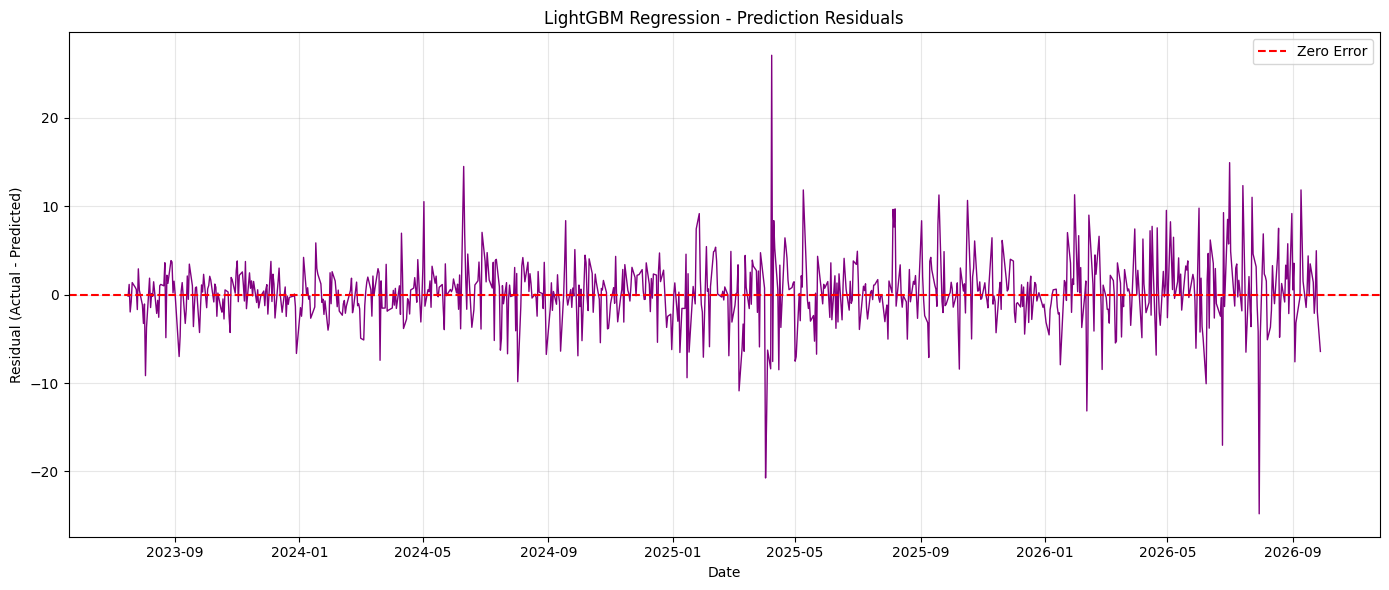

In [14]:
# ------------------------------------------------------------
# BIỂU ĐỒ 4: SAI SỐ DỰ BÁO THEO THỜI GIAN
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    dates_test,
    residuals,
    color="purple",
    linewidth=1
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.title("LightGBM Regression - Prediction Residuals")
plt.xlabel("Date")
plt.ylabel("Residual (Actual - Predicted)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Biểu đồ 5: Mức độ ảnh hưởng của 8 Feature (Feature Importance)

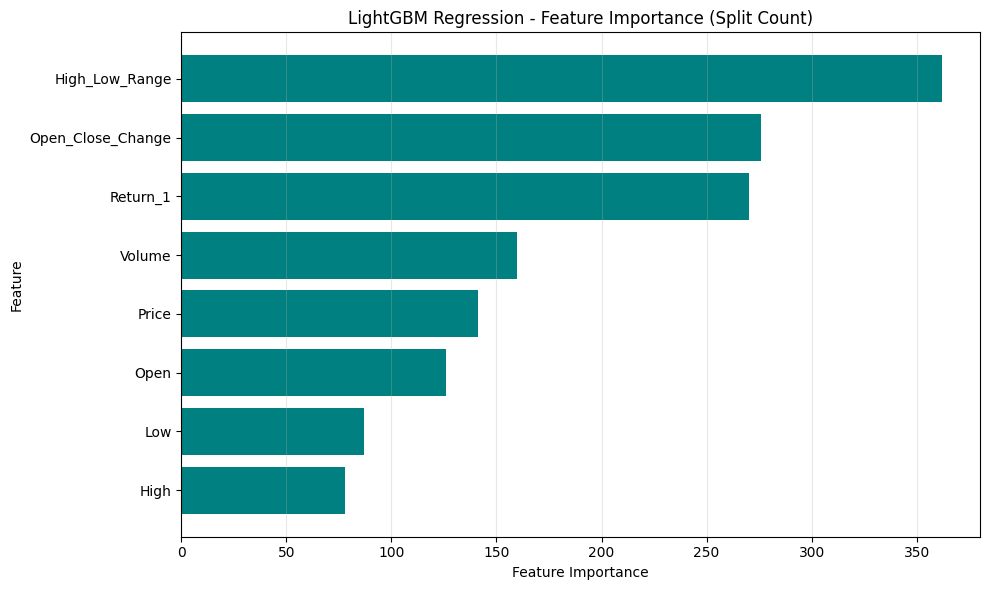

In [15]:
# ------------------------------------------------------------
# BIỂU ĐỒ 5: MỨC ĐỘ ẢNH HƯỞNG CỦA 8 FEATURE
# ------------------------------------------------------------

best_model = lgb_model.best_estimator_
importances = best_model.feature_importances_

feat_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": importances
}).sort_values("Importance")

plt.figure(figsize=(10, 6))

plt.barh(
    feat_df["Feature"],
    feat_df["Importance"],
    color="teal"
)

plt.title("LightGBM Regression - Feature Importance (Split Count)")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()